
# 6강 · Keras로 음성 인식 모델 구성하기

5강의 X·y를 이어 받아 입력 전처리, 정답 구성, Encoder–Decoder, 학습과 자유 생성까지 연결합니다.

**학습 목표:** 각 배열의 의미를 설명하고 Keras 모델을 직접 구성하여 가중치 업데이트와 추론을 확인한다.

| 구성 | 핵심 질문 | 완료 결과 |
|---|---|---|
| 1교시 | 저장 음성을 같은 규칙으로 모델에 넣을 수 있는가? | Log-Mel 대조·정규화·음성 마스크 |
| 2교시 | 다음 토큰을 예측하도록 정답을 어떻게 구성하는가? | BOS/EOS·Decoder 입력·정답·PAD 처리 |
| 3교시 | Keras의 층 사이에서 배열이 어떻게 흐르는가? | Encoder–Decoder·순전파·마스크 동작 확인 |
| 4교시 | 학습과 실제 생성은 무엇이 다른가? | fit·가중치 변화·한 단계 추론·새 음성 실험·결과 보고 |

**범위:** 5강 배치의 음성 3개를 모두 학습에 사용하는 소규모 구조 실습이다. 모델은 실제로 학습하지만 새로운 음성의 인식 성능을 보장하지 않는다. 4-S에서 학습에 쓰지 않은 음성 2개로 이 한계를 직접 확인하고, 7강에서는 사전학습된 Whisper를 사용한다.

**실행 시간:** CPU 기준 전체 2분 안팎이며, 대부분은 4-2 학습(약 1분)이다.


<a id="practice-0"></a>
## 실습 0 · 준비 · 환경과 데이터 경로 [기본 실습]

**이론 연결:** [HTML 0 · 준비 · 환경과 데이터 경로](lesson06_theory.html#practice-0)

**실행 목적:** GPU 목록이 비어 있어도 진행할 수 있습니다. 필수 파일 세 개는 모두 있어야 합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [1]:
# 라이브러리 불러오기
from pathlib import Path
from math import gcd
import json, hashlib, copy, platform
import numpy as np
from scipy.io import wavfile
from scipy.signal import stft, resample_poly
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(0)  # 실행마다 같은 결과가 나오도록 고정

# 실습 폴더 위치
BASE = Path.cwd()  # 필요하면 5강 실습 폴더의 절대 경로로 변경
DATA = BASE / "data"
RESULTS = BASE / "results"
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("실습 폴더:", BASE)
# 세 파일이 모두 True여야 다음으로 진행합니다.
for p in [DATA/'speech_manifest.json', RESULTS/'lesson05_batch.npz', RESULTS/'lesson05_record.json']:
    print(p.name, p.is_file())
print("GPU:", tf.config.list_physical_devices('GPU'))  # []이어도 진행 가능

Python: 3.9.21 TensorFlow: 2.19.0
실습 폴더: G:\OneDrive\AISource\2026_구름\음성\수업자료\6일차
speech_manifest.json True
lesson05_batch.npz True
lesson05_record.json True
GPU: []


### 관찰·직접 적용 · 0

세 경로의 True 여부와 실행 중인 TensorFlow 버전을 기록하세요. False인 경로가 있으면 1-1 이전에 수정하세요.

**완료 기준:** GPU 목록이 비어 있어도 진행할 수 있습니다. 필수 파일 세 개는 모두 있어야 합니다.

### 내 기록 · 0

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 0 — 먼저 자신의 기록을 작성하세요</summary>

노트북이 놓인 위치와 커널의 현재 작업 폴더가 다를 수 있습니다. BASE는 실제 data·results가 있는 폴더를 가리켜야 합니다.

</details>

<a id="practice-1-1"></a>
## 실습 1-1 · 5강 저장 결과와 원본 연결 [기본 실습]

**이론 연결:** [HTML 1-1 · 5강 저장 결과와 원본 연결](lesson06_theory.html#practice-1-1)

**실행 목적:** 5강 기본 선택을 유지했다면 B=3, Mel 특징 수=40입니다. 길이는 저장 결과에 따라 읽습니다. 목록에 있는 나머지 음성 파일도 함께 확인합니다(4-S에서 사용).

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [2]:
# 5강 기록과 음성 목록 읽기
record = json.loads((RESULTS/'lesson05_record.json').read_text(encoding='utf-8'))
manifest = json.loads((DATA/'speech_manifest.json').read_text(encoding='utf-8'))
if not isinstance(manifest, list) or not manifest:
    raise ValueError("5강 Manifest는 항목 리스트여야 합니다.")

# ID → 항목 사전 만들기 (빈 값·중복 ID 검사)
by_id = {}
for row in manifest:
    for key in ('id', 'file', 'reference'):
        if not isinstance(row.get(key), str) or not row[key].strip():
            raise ValueError(f"비어 있거나 잘못된 항목: {key}")
    if row['id'] in by_id:
        raise ValueError("중복 ID")
    by_id[row['id']] = row

# 5강에서 저장한 배열
with np.load(RESULTS/'lesson05_batch.npz', allow_pickle=False) as saved:
    X_raw = saved['batch'].astype('float32')      # (B, T, 40) 음성 특징
    X_mask = saved['mask'].astype(bool)           # (B, T) 실제 프레임 True
    X_lengths = saved['lengths'].astype('int32')  # 음성별 실제 프레임 수
    y5 = saved['label_ids'].astype('int32')       # 정답 어절 ID
    y5_mask = saved['label_mask'].astype(bool)    # 실제 어절 위치 True
    ids = saved['batch_ids'].tolist()             # 각 행의 음성 ID

# 저장 결과끼리 순서·내용이 맞는지 확인
assert ids == record['batch_ids'], "NPZ·JSON의 ID 순서가 다릅니다."
assert len(ids) == len(set(ids)) and len(ids) > 0
rows = [by_id[i] for i in ids]
references = [r['reference'] for r in rows]
assert references == record['references'], "원본 정답과 저장 정답이 다릅니다."
vocab5 = {word: int(idx) for word, idx in record['vocab'].items()}

# 목록의 모든 WAV 확인 (4-S에서 학습에 쓰지 않은 음성도 사용)
for row in manifest:
    relative = Path(row['file'])
    p = (DATA/relative).resolve()
    if relative.is_absolute() or not p.is_relative_to(DATA.resolve()):
        raise ValueError("data 안의 상대 경로를 사용하세요.")
    if not p.is_file():
        raise FileNotFoundError(p)
    if 'sha256' in row:  # 파일 내용이 바뀌지 않았는지 확인
        assert hashlib.sha256(p.read_bytes()).hexdigest() == row['sha256'], "원본 변경"
print("사용 ID:", ids)
print("X:", X_raw.shape, "y5:", y5.shape, "프레임 수:", X_lengths)
print("학습에 쓰지 않은 음성 수:", len(manifest) - len(ids))

사용 ID: ['1272-128104-0001', '1272-128104-0006', '1272-128104-0008']
X: (3, 1290, 40) y5: (3, 17) 프레임 수: [ 609  792 1290]
학습에 쓰지 않은 음성 수: 2


### 관찰·직접 적용 · 1-1

첫 번째 ID의 원본 파일명·정답·실제 프레임 수를 찾아 기록하세요.

**완료 기준:** 5강 기본 선택을 유지했다면 B=3, Mel 특징 수=40입니다. 길이는 저장 결과에 따라 읽습니다.

### 내 기록 · 1-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-1 — 먼저 자신의 기록을 작성하세요</summary>

ID는 음성 종류나 정답 단어의 번호가 아니라 자료 한 건의 식별자입니다. 같은 ID로 WAV·X·y를 연결합니다.

</details>

<a id="practice-1-2"></a>
## 실습 1-2 · 설정 분리와 PCM16 음성 읽기 [기본 실습]

**이론 연결:** [HTML 1-2 · 설정 분리와 PCM16 음성 읽기](lesson06_theory.html#practice-1-2)

**실행 목적:** 원본 녹음과 같은 내용이 들리고 배열은 1차원입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [3]:
# 전처리 설정 (5강과 같아야 함)
CFG = dict(sr=16000, n_fft=512, hop=128, n_mels=40, floor=1e-10)
expected_preprocessing = {
    'sample_rate':16000, 'channels':1, 'window':'hann', 'frame_samples':512,
    'hop_samples':128, 'n_fft':512, 'n_mels':40, 'mel_scale':'HTK',
    'log_floor':1e-10, 'scaling':'spectrum', 'boundary':None, 'padded':False,
    'feature_order':['time','mel'], 'audio_pad_value':0.0,
}
for key, value in expected_preprocessing.items():
    assert key in record['preprocessing'] and record['preprocessing'][key] == value, f"5강 설정 확인: {key}"

def read_mono(path, cfg=CFG):
    # WAV → 16kHz 모노 float32 배열(-1~1)
    sr, pcm = wavfile.read(path)
    if pcm.dtype != np.int16 or pcm.ndim not in (1, 2) or pcm.size == 0:
        raise ValueError(f"{path}: 비어 있지 않은 PCM16 WAV 필요")
    if sr <= 0 or (pcm.ndim == 2 and pcm.shape[1] not in (1, 2)):
        raise ValueError("SR 또는 채널 수를 확인하세요.")
    sound = pcm.astype(np.float32) / 32768.0   # 정수 → -1~1
    if sound.ndim == 2:
        sound = sound.mean(axis=1)             # 스테레오 → 모노
    if sr != cfg['sr']:                        # 다른 SR이면 16kHz로 변환
        divisor = gcd(int(sr), cfg['sr'])
        sound = resample_poly(sound, cfg['sr']//divisor, int(sr)//divisor)
    sound = np.asarray(sound, dtype=np.float32)
    if len(sound) < cfg['n_fft'] or not np.isfinite(sound).all():
        raise ValueError("512샘플 이상인 유효한 음성 필요")
    return sound

sound0 = read_mono(DATA/rows[0]['file'])
print("모노 샘플:", sound0.shape, "길이(초):", len(sound0)/CFG['sr'])
display(Audio(sound0, rate=CFG['sr'], normalize=False))

모노 샘플: (78336,) 길이(초): 4.896


### 관찰·직접 적용 · 1-2

재생한 말과 references[0]을 비교하세요. 512샘플 미만을 거절하는 이유와 SR 숫자만 바꾸면 안 되는 이유를 기록하세요.

**완료 기준:** 원본 녹음과 같은 내용이 들리고 배열은 1차원입니다.

### 내 기록 · 1-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-2 — 먼저 자신의 기록을 작성하세요</summary>

512샘플은 한 분석 창의 길이입니다. 여기서는 부족 구간을 자동 패딩하지 않으므로 최소 한 창이 필요합니다.

</details>

<a id="practice-1-3"></a>
## 실습 1-3 · Log-Mel 함수와 저장 특징 대조 [기본 실습]

**이론 연결:** [HTML 1-3 · Log-Mel 함수와 저장 특징 대조](lesson06_theory.html#practice-1-3)

**실행 목적:** 원본·설정이 같으면 저장 특징과 거의 일치합니다. 프레임별 40개의 특징이 생깁니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

1272-128104-0001 (609, 40) 최대 절대 차이: 0.0
1272-128104-0006 (792, 40) 최대 절대 차이: 0.0
1272-128104-0008 (1290, 40) 최대 절대 차이: 0.0


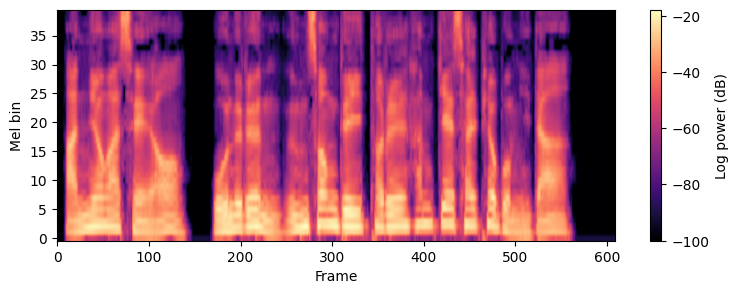

In [4]:
def extract_logmel(sound, cfg=CFG):
    # 파형 → Log-Mel 특징 (프레임 수, 40)
    # 1) STFT: 512샘플 창을 128샘플씩 밀며 주파수 분석
    hz, times, z = stft(sound, fs=cfg['sr'], window='hann',
        nperseg=cfg['n_fft'], noverlap=cfg['n_fft']-cfg['hop'], nfft=cfg['n_fft'],
        boundary=None, padded=False, detrend=False, scaling='spectrum')
    power = np.abs(z)**2                     # 2) 파워
    # 3) Mel 필터 40개 만들기 (HTK 방식)
    to_mel = lambda f: 2595*np.log10(1+f/700)
    to_hz = lambda m: 700*(10**(m/2595)-1)
    edges = to_hz(np.linspace(0, to_mel(cfg['sr']/2), cfg['n_mels']+2))
    filters = np.zeros((cfg['n_mels'], len(hz)))
    for k in range(cfg['n_mels']):
        left, center, right = edges[k:k+3]
        filters[k] = np.maximum(0, np.minimum((hz-left)/(center-left), (right-hz)/(right-center)))
    mel_power = filters @ power              # 4) Mel 대역으로 묶기
    # 5) dB로 바꾸고 (시간, Mel) 순서로 전치
    features = (10*np.log10(np.maximum(mel_power, cfg['floor']))).T.astype('float32')
    assert features.shape == (1+(len(sound)-cfg['n_fft'])//cfg['hop'], cfg['n_mels'])
    return features

# 다시 계산한 특징과 5강 저장값 비교
recomputed = [extract_logmel(read_mono(DATA/r['file'])) for r in rows]
for i, feat in enumerate(recomputed):
    stored = X_raw[i, X_mask[i]]   # 패딩을 뺀 저장값
    assert feat.shape == stored.shape, f"{ids[i]} 프레임 불일치"
    assert np.allclose(feat, stored, atol=1e-4, rtol=1e-5), f"{ids[i]} 특징 설정 불일치"
    print(ids[i], feat.shape, "최대 절대 차이:", float(np.max(np.abs(feat-stored))))
plt.figure(figsize=(9,3))
plt.imshow(recomputed[0].T, origin='lower', aspect='auto', cmap='magma')
plt.xlabel('Frame'); plt.ylabel('Mel bin'); plt.colorbar(label='Log power (dB)'); plt.show()

### 관찰·직접 적용 · 1-3

그림의 가로축과 세로축이 의미하는 것을 적고, Mel 수만 바꾸었을 때 기존 모델과 호환되지 않는 이유를 설명하세요.

**완료 기준:** 원본·설정이 같으면 저장 특징과 거의 일치합니다. 프레임별 40개의 특징이 생깁니다.

### 내 기록 · 1-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-3 — 먼저 자신의 기록을 작성하세요</summary>

가로는 시간 프레임, 세로는 Mel 대역입니다. n_mels를 바꾸면 입력의 마지막 차원과 특징의 의미가 모두 바뀝니다.

</details>

<a id="practice-1-4"></a>
## 실습 1-4 · 유효 프레임 정규화와 배치 검사 [직접 변경]

**이론 연결:** [HTML 1-4 · 유효 프레임 정규화와 배치 검사](lesson06_theory.html#practice-1-4)

**실행 목적:** 정규화한 유효 구간 평균은 대략 0입니다. 분산이 0인 대역은 정규화 뒤에도 0입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [5]:
B, T, M = X_raw.shape   # 음성 수, 최대 프레임 수, Mel 수
assert M == CFG['n_mels'] and X_mask.shape == (B,T)
assert np.isfinite(X_raw).all() and np.all(X_lengths > 0)
# 마스크가 '앞은 True, 뒤는 False'인지 확인
expected_mask = np.arange(T)[None,:] < X_lengths[:,None]
assert np.array_equal(X_mask, expected_mask), "오른쪽 패딩 규칙 확인"
assert np.all(X_raw[~X_mask] == 0)
# 실제 프레임만으로 평균·표준편차 계산 (전체 시연 배치를 학습 데이터로 사용)
valid_frames = X_raw[X_mask]
feature_mean = valid_frames.mean(axis=0).astype('float32')
feature_std = np.maximum(valid_frames.std(axis=0), 1e-5).astype('float32')
# 표준화 후 패딩은 다시 0
X = np.where(X_mask[...,None], (X_raw-feature_mean)/feature_std, 0).astype('float32')
print("X:", X.shape, X.dtype, "mask:", X_mask.shape)
print("유효 구간 평균 절댓값 최대:", float(np.abs(X[X_mask].mean(axis=0)).max()))
print("패딩 비율:", float((~X_mask).mean()))
assert np.isfinite(X).all() and np.all(X[~X_mask] == 0)

X: (3, 1290, 40) float32 mask: (3, 1290)
유효 구간 평균 절댓값 최대: 5.5322680054814555e-06
패딩 비율: 0.30465116279069765


### 관찰·직접 적용 · 1-4

패딩을 포함한 평균과 제외한 평균의 차이를 아래 셀에서 비교하세요. 그 차이가 실제로 생기는지 숫자로 기록하세요.

**완료 기준:** 정규화한 유효 구간 평균은 대략 0입니다. 분산이 0인 대역은 정규화 뒤에도 0입니다.

In [6]:
# 패딩(0)까지 넣어 계산한 평균과 비교
mean_with_pad = X_raw.mean(axis=(0,1))
print('패딩 포함/제외 평균 차이 최대:',float(np.abs(mean_with_pad-feature_mean).max()))


패딩 포함/제외 평균 차이 최대: 24.607669830322266


### 내 기록 · 1-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-4 — 먼저 자신의 기록을 작성하세요</summary>

패딩을 넣은 평균은 실제 녹음 특성 대신 배치의 패딩 양에 영향을 받습니다. 두 평균이 우연히 같더라도 유효 프레임만 쓰는 원칙은 유지합니다.

</details>

<a id="practice-2-1"></a>
## 실습 2-1 · 기존 어절 ID 유지와 특수 토큰 추가 [기본 실습]

**이론 연결:** [HTML 2-1 · 기존 어절 ID 유지와 특수 토큰 추가](lesson06_theory.html#practice-2-1)

**실행 목적:** 기존 ID는 동일하고 사전 크기는 2만큼 증가합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [7]:
def tokenize(text):
    # 5강 규칙: 양끝 공백 제거 → 문장 끝 .!? 제거 → 공백으로 나누기
    return text.strip().rstrip('.!?').split()
assert vocab5.get('<pad>') == 0 and vocab5.get('<unk>') == 1
assert set(vocab5.values()) == set(range(len(vocab5))), "사전 ID는 중복 없는 연속 번호여야 합니다."
assert y5.shape == y5_mask.shape and y5.shape[0] == B
assert np.all(y5[~y5_mask] == 0)
lengths5 = y5_mask.sum(axis=1)
assert np.array_equal(y5_mask, np.arange(y5.shape[1])[None,:] < lengths5[:,None])
inverse5 = {v:k for k,v in vocab5.items()}   # ID → 어절
token_sequences = []
for i, text in enumerate(references):
    seq = y5[i,y5_mask[i]].tolist()          # 패딩을 뺀 정답 ID
    if not seq or any(t not in inverse5 or t in (0,1) for t in seq):
        raise ValueError("시연 정답에 빈 문장·PAD·UNK 또는 잘못된 ID가 있습니다.")
    assert [inverse5[t] for t in seq] == tokenize(text), "정답 ID와 원문 불일치"
    token_sequences.append(seq)
# 기존 ID는 그대로 두고 BOS·EOS만 맨 뒤에 추가
vocab = dict(vocab5)
assert '<bos>' not in vocab and '<eos>' not in vocab
vocab['<bos>'] = len(vocab)
vocab['<eos>'] = len(vocab)
PAD, UNK, BOS, EOS = [vocab[t] for t in ('<pad>','<unk>','<bos>','<eos>')]
inverse = {v:k for k,v in vocab.items()}
V = len(vocab)   # 사전 크기
print("사전 크기:", V, "특수 ID:", PAD, UNK, BOS, EOS)
print("첫 정답 ID:", token_sequences[0])
print("되읽기:", ' '.join(inverse[t] for t in token_sequences[0]))

사전 크기: 35 특수 ID: 0 1 33 34
첫 정답 ID: [2, 3, 4, 5, 6, 7]
되읽기: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다


### 관찰·직접 적용 · 2-1

5강의 첫 어절 ID가 바뀌지 않았는지 확인하고 BOS·EOS를 추가한 이유를 각각 적으세요.

**완료 기준:** 기존 ID는 동일하고 사전 크기는 2만큼 증가합니다.

### 내 기록 · 2-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-1 — 먼저 자신의 기록을 작성하세요</summary>

BOS는 첫 단어를 예측하기 위한 입력, EOS는 문장 생성이 끝났음을 학습하기 위한 정답입니다.

토큰화 규칙은 문장 **끝**의 부호만 지우므로 `안녕하세요.`처럼 문장 중간의 마침표는 어절에 남습니다. 5강 사전이 이 규칙으로 만들어졌기 때문에 6강에서 규칙을 바꾸면 ID가 맞지 않습니다.

</details>

<a id="practice-2-2"></a>
## 실습 2-2 · Decoder 입력과 한 칸 이동한 정답 [기본 실습]

**이론 연결:** [HTML 2-2 · Decoder 입력과 한 칸 이동한 정답](lesson06_theory.html#practice-2-2)

**실행 목적:** 목표의 마지막 유효 토큰은 EOS이며 입력·정답은 한 칸 어긋납니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [8]:
def make_decoder_batch(sequences):
    # 정답 → Decoder 입력([BOS]+정답), 목표(정답+[EOS]), PAD 아닌 위치
    width = max(map(len, sequences)) + 1
    dec_in = np.full((len(sequences),width), PAD, dtype=np.int32)
    target = np.full_like(dec_in, PAD)
    for i, seq in enumerate(sequences):
        n = len(seq)+1
        dec_in[i,:n] = [BOS]+seq     # 예: [BOS, A, B, C]
        target[i,:n] = seq+[EOS]     # 예: [A, B, C, EOS]
    return dec_in, target, target != PAD

decoder_in, decoder_target, target_mask = make_decoder_batch(token_sequences)
U = decoder_in.shape[1]   # 출력 위치 수
for i in range(B):
    n = len(token_sequences[i])+1
    assert decoder_in[i,0] == BOS and decoder_target[i,n-1] == EOS
    assert np.array_equal(decoder_in[i,1:n], decoder_target[i,:n-1])   # 한 칸 어긋남
    assert target_mask[i].sum() == n
print("decoder_in:", decoder_in.shape, "target:", decoder_target.shape)
print("첫 입력:", [inverse[int(t)] for t in decoder_in[0]])
print("첫 정답:", [inverse[int(t)] for t in decoder_target[0]])

decoder_in: (3, 18) target: (3, 18)
첫 입력: ['<bos>', '안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
첫 정답: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


### 관찰·직접 적용 · 2-2

첫 문장의 각 위치를 ‘입력 토큰 → 목표 토큰’으로 나란히 출력하고, 마지막 유효 위치의 정답을 확인하세요.

**완료 기준:** 목표의 마지막 유효 토큰은 EOS이며 입력·정답은 한 칸 어긋납니다.

In [9]:
# 위치별 '입력 → 맞혀야 할 토큰'
for pos in range(int(target_mask[0].sum())):
    print(pos, inverse[int(decoder_in[0,pos])], '→', inverse[int(decoder_target[0,pos])])


0 <bos> → 안녕하세요.
1 안녕하세요. → 오늘은
2 오늘은 → 음성
3 음성 → 데이터를
4 데이터를 → 함께
5 함께 → 살펴봅니다
6 살펴봅니다 → <eos>


### 내 기록 · 2-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-2 — 먼저 자신의 기록을 작성하세요</summary>

입력과 정답을 동일하게 만들면 현재 토큰 복사 문제가 되므로 다음 토큰 예측을 배울 수 없습니다.

</details>

<a id="practice-2-3"></a>
## 실습 2-3 · 학습 데이터 계약과 오류 찾기 [직접 변경]

**이론 연결:** [HTML 2-3 · 학습 데이터 계약과 오류 찾기](lesson06_theory.html#practice-2-3)

**실행 목적:** V는 사전 크기이므로 유효 ID의 최댓값은 V-1입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [10]:
def check_training_arrays(audio, audio_mask, dec_in, target, vocab_size):
    # 학습 직전 배열의 모양·자료형·값 범위 점검
    assert audio.ndim == 3 and audio.shape[2] == CFG['n_mels']
    assert audio.shape[:2] == audio_mask.shape
    assert dec_in.shape == target.shape and len(audio) == len(target)
    assert audio.dtype == np.float32 and audio_mask.dtype == bool
    assert dec_in.dtype == np.int32 and target.dtype == np.int32
    assert np.isfinite(audio).all() and audio_mask.any(axis=1).all()
    assert np.all((dec_in >= 0) & (dec_in < vocab_size)), "입력 ID 범위 오류"
    assert np.all((target >= 0) & (target < vocab_size)), "정답 ID 범위 오류"
    assert np.all(dec_in[:,0] == BOS)
    assert (target != PAD).any(axis=1).all()
    return True
print("배열 계약 통과:", check_training_arrays(X, X_mask, decoder_in, decoder_target, V))
# 복사본에 범위 밖 ID(V)를 넣어 검사가 잡는지 확인
bad_in = decoder_in.copy()
bad_in[0,0] = V
try:
    check_training_arrays(X, X_mask, bad_in, decoder_target, V)
except AssertionError as error:
    print("예상한 검사 실패:", error)

배열 계약 통과: True
예상한 검사 실패: 입력 ID 범위 오류


### 관찰·직접 적용 · 2-3

다른 복사본에서 정답 행을 뒤집어 보세요. 모양 검사만으로 정답 연결 오류를 찾을 수 있는지 판단하세요.

**완료 기준:** V는 사전 크기이므로 유효 ID의 최댓값은 V-1입니다.

In [11]:
# 정답 행 순서만 뒤집은 복사본 → 모양 검사는 통과할까?
reversed_target = decoder_target[::-1].copy()
print('행을 바꾼 정답도 모양 검사 통과:',check_training_arrays(X,X_mask,decoder_in,reversed_target,V))
print('이 출력은 ID·의미 연결이 맞다는 뜻이 아닙니다.')


행을 바꾼 정답도 모양 검사 통과: True
이 출력은 ID·의미 연결이 맞다는 뜻이 아닙니다.


### 내 기록 · 2-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-3 — 먼저 자신의 기록을 작성하세요</summary>

행을 뒤집으면 모양이 같아 검사를 통과할 수 있습니다. ID와 정답 원문 대조는 배열 모양 검사와 다른 책임입니다.

</details>

<a id="practice-2-4"></a>
## 실습 2-4 · 한 자료를 끝까지 추적하기 [직접 변경]

**이론 연결:** [HTML 2-4 · 한 자료를 끝까지 추적하기](lesson06_theory.html#practice-2-4)

**실행 목적:** 선택 ID의 정답과 토큰열이 연결되며, X의 프레임 수와 정답 토큰 수는 다릅니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [12]:
ROW = 0  # 다른 행으로 바꿔 추적하세요.
assert 0 <= ROW < B
n = int(target_mask[ROW].sum())
print("ID:", ids[ROW], "파일:", rows[ROW]['file'])
print("원문:", references[ROW])
print("패딩 전 X:", X[ROW,X_mask[ROW]].shape)
for position in range(n):
    print(position, inverse[int(decoder_in[ROW,position])], '→', inverse[int(decoder_target[ROW,position])])
print("전체 음성 시간 칸:", T, "전체 출력 위치:", U)

ID: 1272-128104-0001 파일: speech/1272-128104-0001.wav
원문: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
패딩 전 X: (609, 40)
0 <bos> → 안녕하세요.
1 안녕하세요. → 오늘은
2 오늘은 → 음성
3 음성 → 데이터를
4 데이터를 → 함께
5 함께 → 살펴봅니다
6 살펴봅니다 → <eos>
전체 음성 시간 칸: 1290 전체 출력 위치: 18


### 관찰·직접 적용 · 2-4

다른 ID를 선택하여 데이터 흐름을 설명하세요. T와 U가 달라도 정상인 이유를 적으세요.

**완료 기준:** 선택 ID의 정답과 토큰열이 연결되며, X의 프레임 수와 정답 토큰 수는 다릅니다.

### 내 기록 · 2-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-4 — 먼저 자신의 기록을 작성하세요</summary>

한 프레임이 한 어절에 대응하지 않습니다. 여러 음성 프레임에 걸친 발화 정보를 모델이 처리해 토큰을 예측합니다.

</details>

<a id="practice-2-S"></a>
## 실습 2-S · 사전 밖 어절과 추론의 한계 [자율실습]

**이론 연결:** [HTML 2-S · 사전 밖 어절과 추론의 한계](lesson06_theory.html#practice-2-S)

**실행 목적:** 기존 어절은 기존 ID, 미등록 어절은 1입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [14]:
NEW_SENTENCE = '새로운 장비를 점검합니다'   # 원하는 문장으로 바꿔 보세요.
new_words = tokenize(NEW_SENTENCE)
new_ids = [vocab.get(word,UNK) for word in new_words]   # 없으면 UNK
for word, token_id in zip(new_words,new_ids):
    print(word,'→',token_id,'→',inverse[token_id])
unknown_rate = sum(t == UNK for t in new_ids)/len(new_ids) if new_ids else 0
print('미등록 어절 비율:',unknown_rate)

새로운 → 1 → <unk>
장비를 → 1 → <unk>
점검합니다 → 1 → <unk>
미등록 어절 비율: 1.0


### 관찰·직접 적용 · 2-S

기존 정답의 일부 어절과 사전에 없는 어절을 섞은 문장으로 바꾸세요. 사전만 수정하면 되는지 설명하세요.

**완료 기준:** 기존 어절은 기존 ID, 미등록 어절은 1입니다.

### 내 기록 · 2-S

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-S — 먼저 자신의 기록을 작성하세요</summary>

Embedding 행 수와 Dense 출력 수가 V에 맞춰져 있습니다. 사전의 번호·크기 변경은 모델까지 다시 설계하거나 학습하는 문제입니다.

</details>

<a id="practice-3-1"></a>
## 실습 3-1 · Encoder 구성과 상태 벡터 [기본 실습]

**이론 연결:** [HTML 3-1 · Encoder 구성과 상태 벡터](lesson06_theory.html#practice-3-1)

**실행 목적:** 입력 (1,T,40)이 상태 h·c 각각 (1,32)로 바뀝니다. 이 Encoder는 `go_backwards=True`로 음성을 **끝에서 앞으로** 읽습니다. 이유는 HTML 3-1과 4-S에서 확인합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [15]:
UNITS = 32       # LSTM 상태 크기
EMBED_DIM = 24   # 토큰 벡터 크기
# 입력 1: 음성 특징 (길이 자유, 프레임당 40개)
audio_input = keras.Input(shape=(None, CFG['n_mels']), dtype='float32', name='audio')
# 입력 2: 음성 마스크 (True인 프레임만 읽음)
audio_mask_input = keras.Input(shape=(None,), dtype='bool', name='audio_mask')
# Encoder: 음성을 끝까지 읽고 마지막 상태 h, c를 돌려줌
# go_backwards=True: 음성을 끝에서 앞으로 읽음 → 마지막 상태에 문장 앞부분 정보가 남음
encoder_lstm = keras.layers.LSTM(UNITS, return_state=True, go_backwards=True, name='encoder_lstm')
encoder_output, state_h, state_c = encoder_lstm(audio_input, mask=audio_mask_input)
encoder_model = keras.Model([audio_input,audio_mask_input], [state_h,state_c], name='encoder')
h0, c0 = encoder_model([X[:1], X_mask[:1]], training=False)   # 첫 음성으로 시험
print("Encoder h:", h0.shape, "c:", c0.shape)
encoder_model.summary()

Encoder h: (1, 32) c: (1, 32)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ audio (InputLayer)            │ (None, None, 40)          │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ audio_mask (InputLayer)       │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ encoder_lstm (LSTM)           │ [(None, 32), (None, 32),  │           9,344 │ audio[0][0],               │
│                               │ (None, 32)]               │                 │ audio_mask[0][0]           │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 9,344 (36.50 KB)

 Trainable params: 9,344 (36.50 KB)

 Non-trainable params: 0 (0.00 B)

### 관찰·직접 적용 · 3-1

units를 늘리면 어떤 배열의 마지막 차원과 파라미터 수가 바뀔지 예상하세요. 기본 실행에서는 32를 유지합니다.

**완료 기준:** 입력 (1,T,40)이 상태 h·c 각각 (1,32)로 바뀝니다.

### 내 기록 · 3-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-1 — 먼저 자신의 기록을 작성하세요</summary>

h와 c는 음성에서 계산한 정보입니다. 고정 길이 상태를 만들기 때문에 Decoder의 토큰 길이는 입력 프레임 수와 같을 필요가 없습니다.

LSTM의 마지막 상태는 마지막에 읽은 부분의 영향을 가장 크게 받습니다. 실습 WAV는 모두 끝에 0.4~0.8초의 완전한 무음이 있어 정방향으로 읽으면 세 음성의 마지막 상태가 같아집니다. 거꾸로 읽으면 마지막에 읽는 부분이 문장의 시작이므로 음성마다 상태가 달라집니다.

</details>

<a id="practice-3-2"></a>
## 실습 3-2 · Embedding과 Decoder 연결 [기본 실습]

**이론 연결:** [HTML 3-2 · Embedding과 Decoder 연결](lesson06_theory.html#practice-3-2)

**실행 목적:** 모델에는 세 입력과 한 출력이 있으며 출력 마지막 축은 사전 크기입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [16]:
# 입력 3: Decoder 토큰 ID
token_input = keras.Input(shape=(None,), dtype='int32', name='decoder_tokens')
embedding_layer = keras.layers.Embedding(V, EMBED_DIM, mask_zero=False, name='token_embedding')
decoder_lstm = keras.layers.LSTM(UNITS, return_sequences=True, return_state=True, name='decoder_lstm')
output_layer = keras.layers.Dense(V, activation='softmax', name='token_probabilities')
embedded = embedding_layer(token_input)                                         # (B, U, 24)
decoder_states, _, _ = decoder_lstm(embedded, initial_state=[state_h,state_c])  # (B, U, 32), 음성 상태로 시작
probabilities = output_layer(decoder_states)                                    # (B, U, V)
model = keras.Model([audio_input,audio_mask_input,token_input], probabilities, name='speech_seq2seq')
model.summary()
print("모델 입력 이름:", [t.name for t in model.inputs])

Model: "speech_seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ decoder_tokens (InputLayer)   │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ audio (InputLayer)            │ (None, None, 40)          │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ audio_mask (InputLayer)       │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_embedding (Embedding)   │ (None, None, 24)          │             840 │ decoder_tokens[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ encoder_lstm (LSTM)           │ [(None, 32), (None, 32),  │           9,344 │ audio[0][0],               │
│                               │ (None, 32)]               │                 │ audio_mask[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder_lstm (LSTM)           │ [(None, None, 32), (None, │           7,296 │ token_embedding[0][0],     │
│                               │ 32), (None, 32)]          │                 │ encoder_lstm[0][1],        │
│                               │                           │                 │ encoder_lstm[0][2]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_probabilities (Dense)   │ (None, None, 35)          │           1,155 │ decoder_lstm[0][0]         │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 18,635 (72.79 KB)

 Trainable params: 18,635 (72.79 KB)

 Non-trainable params: 0 (0.00 B)

모델 입력 이름: ['audio', 'audio_mask', 'decoder_tokens']


### 관찰·직접 적용 · 3-2

Embedding·LSTM·Dense의 입력과 출력 모양을 표로 적고, Dense 출력 차원이 V인 이유를 설명하세요.

**완료 기준:** 모델에는 세 입력과 한 출력이 있으며 출력 마지막 축은 사전 크기입니다.

### 내 기록 · 3-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-2 — 먼저 자신의 기록을 작성하세요</summary>

출력은 정답 ID 하나가 아니라 후보 전체의 확률입니다. 나중에 argmax로 한 후보를 선택합니다.

</details>

<a id="practice-3-3"></a>
## 실습 3-3 · 학습 전 순전파와 확률 해석 [기본 실습]

**이론 연결:** [HTML 3-3 · 학습 전 순전파와 확률 해석](lesson06_theory.html#practice-3-3)

**실행 목적:** 출력은 유효한 확률 분포이지만 학습 전 예측은 정답과 다를 수 있습니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [17]:
train_inputs = [X, X_mask, decoder_in]   # 입력 순서: 음성, 마스크, Decoder 입력
before_probs = model(train_inputs, training=False).numpy()   # 학습 전 예측
assert before_probs.shape == (B,U,V)
assert np.allclose(before_probs.sum(axis=-1), 1, atol=1e-5)   # 위치마다 확률 합 = 1
first_ranking = np.argsort(before_probs[0,0])[::-1][:min(5,V)]   # 상위 5개 후보
print("출력:", before_probs.shape)
for token_id in first_ranking:
    print(inverse[int(token_id)], round(float(before_probs[0,0,token_id]),4))
print("첫 목표 토큰:", inverse[int(decoder_target[0,0])])
weights_before = [w.copy() for w in model.get_weights()]   # 학습 전 가중치 보관

출력: (3, 18, 35)
데이터가 0.0579
데이터를 0.0423
오늘은 0.0406
<pad> 0.0387
배운 0.0375
첫 목표 토큰: 안녕하세요.


### 관찰·직접 적용 · 3-3

첫 위치의 최고 후보와 실제 목표를 비교하세요. 확률 합이 1인 것이 정확한 인식을 뜻하는지 적으세요.

**완료 기준:** 출력은 유효한 확률 분포이지만 학습 전 예측은 정답과 다를 수 있습니다.

### 내 기록 · 3-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-3 — 먼저 자신의 기록을 작성하세요</summary>

softmax는 값들을 확률 분포로 만드는 계산입니다. 정답을 맞히는 능력은 적절한 데이터와 학습에 달려 있습니다.

</details>

<a id="practice-3-4"></a>
## 실습 3-4 · 음성 패딩 마스크의 효과 확인 [직접 변경]

**이론 연결:** [HTML 3-4 · 음성 패딩 마스크의 효과 확인](lesson06_theory.html#practice-3-4)

**실행 목적:** 올바른 마스크를 주면 h·c가 허용 오차 안에서 같습니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [18]:
# 실제 음성 뒤에 가짜 프레임 8개(값 7.0)를 붙이고 마스크로 가리면 결과가 같을까?
length0 = int(X_lengths[0])
x_one = X[:1,:length0]                              # 실제 프레임만
m_one = np.ones((1,length0), dtype=bool)
extra = np.full((1,8,M), 7.0, dtype=np.float32)     # 가짜 프레임
x_more = np.concatenate([x_one,extra], axis=1)
m_more = np.concatenate([m_one,np.zeros((1,8),dtype=bool)], axis=1)   # 가짜는 False
h_a, c_a = encoder_model([x_one,m_one], training=False)
h_b, c_b = encoder_model([x_more,m_more], training=False)
h_wrong, _ = encoder_model([x_more,np.ones_like(m_more)], training=False)   # 마스크 없이(모두 True)
print("우리 Encoder(거꾸로 읽기) - 제외 마스크:", float(np.max(np.abs(h_a.numpy()-h_b.numpy()))),
      " 모두 True:", float(np.max(np.abs(h_a.numpy()-h_wrong.numpy()))))
np.testing.assert_allclose(h_a.numpy(),h_b.numpy(),atol=1e-5,rtol=1e-5)
np.testing.assert_allclose(c_a.numpy(),c_b.numpy(),atol=1e-5,rtol=1e-5)

# 비교: 같은 크기의 정방향 LSTM (모델과 무관한 새 레이어)
forward_probe = keras.layers.LSTM(UNITS, return_state=True, name='forward_probe')
def forward_h(x, m):
    return forward_probe(x, mask=m)[1].numpy()
fh_a = forward_h(x_one, m_one)
print("정방향 LSTM          - 제외 마스크:", float(np.max(np.abs(fh_a-forward_h(x_more,m_more)))),
      " 모두 True:", float(np.max(np.abs(fh_a-forward_h(x_more,np.ones_like(m_more))))))

우리 Encoder(거꾸로 읽기) - 제외 마스크: 0.0  모두 True: 0.0
정방향 LSTM          - 제외 마스크: 0.0  모두 True: 1.2307889461517334


### 관찰·직접 적용 · 3-4

두 줄의 출력을 비교하세요. 우리 Encoder(거꾸로 읽기)와 정방향 LSTM에서 "모두 True"의 결과가 다른 이유를 읽는 순서로 설명하세요.

추가 프레임 값을 -3.0으로 바꾸어 다시 실행하세요. False인 위치의 값이 바뀌어도 상태가 유지되는지 확인하세요.

**완료 기준:** 올바른 마스크를 주면 h·c가 허용 오차 안에서 같습니다.

### 내 기록 · 3-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-4 — 먼저 자신의 기록을 작성하세요</summary>

마스크의 역할은 PAD 값을 특정 숫자로 바꾸는 것이 아니라 해당 위치를 유효 입력으로 취급하지 않게 하는 것입니다. 두 방향 모두 제외 마스크의 차이는 0입니다.

마스크가 없을 때의 차이는 읽는 순서에 달려 있습니다. 정방향 LSTM은 오른쪽 끝의 가짜 프레임을 마지막에 읽어 상태가 크게 바뀝니다. 거꾸로 읽는 Encoder는 가짜 프레임을 가장 먼저 읽고 609프레임 동안 잊어버립니다. 그래도 마스크는 항상 넣습니다. 패딩이 길거나 모델의 기억이 길어지면 영향이 남을 수 있고, 마스크는 그런 우연에 기대지 않는 약속이기 때문입니다.

</details>

<a id="practice-4-1"></a>
## 실습 4-1 · PAD를 제외한 토큰 손실 [기본 실습]

**이론 연결:** [HTML 4-1 · PAD를 제외한 토큰 손실](lesson06_theory.html#practice-4-1)

**실행 목적:** -ln(0.1)은 약 2.303, -ln(0.8)은 약 0.223입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [20]:
@keras.utils.register_keras_serializable(package='SpeechLesson')
def masked_token_loss(y_true, y_pred):
    # PAD를 뺀 위치의 교차 엔트로피를 문장별로 평균
    y_true = tf.cast(y_true, tf.int32)
    valid = tf.cast(tf.not_equal(y_true, PAD), tf.float32)        # PAD가 아니면 1
    per_token = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)   # -log(정답 확률)
    return tf.math.divide_no_nan(tf.reduce_sum(per_token*valid,axis=-1), tf.reduce_sum(valid,axis=-1))

@keras.utils.register_keras_serializable(package='SpeechLesson')
def masked_token_accuracy(y_true, y_pred):
    # PAD를 뺀 위치의 정답률을 문장별로 계산
    y_true = tf.cast(y_true, tf.int32)
    chosen = tf.argmax(y_pred,axis=-1,output_type=tf.int32)
    valid = tf.cast(tf.not_equal(y_true,PAD),tf.float32)
    correct = tf.cast(tf.equal(chosen,y_true),tf.float32)*valid
    return tf.math.divide_no_nan(tf.reduce_sum(correct,axis=-1),tf.reduce_sum(valid,axis=-1))

base_loss = masked_token_loss(decoder_target,before_probs).numpy()
# PAD 3칸을 더 붙여도 손실이 같은지 확인
padded_targets = np.pad(decoder_target,((0,0),(0,3)),constant_values=PAD)
uniform = np.full((B,3,V),1/V,dtype=np.float32)
padded_probs = np.concatenate([before_probs,uniform],axis=1)
np.testing.assert_allclose(base_loss,masked_token_loss(padded_targets,padded_probs).numpy(),rtol=1e-5)
print("문장별 손실:",base_loss, "평균:",float(base_loss.mean()))
print("PAD를 3위치 추가해도 손실은 같습니다.")

문장별 손실: [3.554981  3.5901747 3.6160748] 평균: 3.5870769023895264
PAD를 3위치 추가해도 손실은 같습니다.


### 관찰·직접 적용 · 4-1

정답 확률 0.1과 0.8의 -log 값을 계산하세요. PAD 추가 후 손실이 작아지지 않는 이유도 설명하세요.

**완료 기준:** -ln(0.1)은 약 2.303, -ln(0.8)은 약 0.223입니다.

In [21]:
# 정답 확률과 손실의 관계
print('정답 확률 0.1의 손실:',-np.log(0.1))
print('정답 확률 0.8의 손실:',-np.log(0.8))


정답 확률 0.1의 손실: 2.3025850929940455
정답 확률 0.8의 손실: 0.2231435513142097


### 내 기록 · 4-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-1 — 먼저 자신의 기록을 작성하세요</summary>

정답 확률이 높을수록 손실은 작습니다. 분모와 분자에서 PAD를 제외하므로 PAD를 늘려도 손실이 희석되지 않습니다.

</details>

<a id="practice-4-2"></a>
## 실습 4-2 · compile·fit과 가중치 업데이트 [기본 실습]

**이론 연결:** [HTML 4-2 · compile·fit과 가중치 업데이트](lesson06_theory.html#practice-4-2)

**실행 목적:** 가중치 변화가 0보다 커지고 손실이 내려갑니다. 이 셀은 실행할 때마다 학습 전 가중치로 되돌린 뒤 학습하므로, 설정을 바꿔 다시 실행해도 같은 출발점에서 비교할 수 있습니다. 기본 설정(학습률 0.01, 60 epoch)은 CPU에서 약 1분 걸립니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

학습 시간: 15.2초
epoch   1  loss 3.5871  accuracy 0.0303
epoch  11  loss 2.3780  accuracy 0.3963
epoch  21  loss 1.3563  accuracy 0.7357
epoch  31  loss 0.7725  accuracy 0.9630
epoch  41  loss 0.4022  accuracy 0.9815
epoch  51  loss 0.2009  accuracy 1.0000
epoch  60  loss 0.1114  accuracy 1.0000
학습 전 대비 가중치 변화 최대: 0.7578209638595581


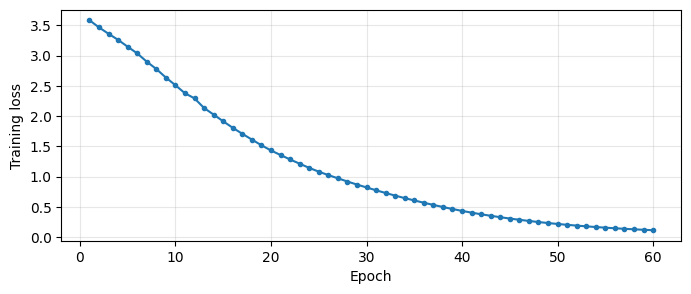

In [22]:
import time
LEARNING_RATE = 0.01   # 한 번에 가중치를 고치는 크기
EPOCHS = 60          # 동작만 확인할 때는 2

# 이 셀은 실행할 때마다 학습 전 가중치로 되돌린 뒤 학습합니다. (설정을 바꿔 다시 실행해도 공정하게 비교)
model.set_weights(weights_before)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
              loss=masked_token_loss, metrics=[masked_token_accuracy])
# 세 입력과 정답을 함께 묶어 공급 (전체 3개를 한 배치로 → epoch마다 업데이트 1회)
train_ds = tf.data.Dataset.from_tensor_slices(((X,X_mask,decoder_in),decoder_target)).batch(B)
options = tf.data.Options()
options.threading.private_threadpool_size = 1
train_ds = train_ds.with_options(options)
start = time.time()
history = model.fit(train_ds, epochs=EPOCHS, callbacks=[keras.callbacks.TerminateOnNaN()], verbose=0)
print(f"학습 시간: {time.time()-start:.1f}초")
# 10 epoch마다 기록 출력
for epoch in sorted(set(range(0, EPOCHS, 10)) | {EPOCHS-1}):
    print(f"epoch {epoch+1:3d}  loss {history.history['loss'][epoch]:.4f}  "
          f"accuracy {history.history['masked_token_accuracy'][epoch]:.4f}")
max_weight_change = max(float(np.max(np.abs(a-b))) for a,b in zip(weights_before,model.get_weights()))
print("학습 전 대비 가중치 변화 최대:",max_weight_change)
assert max_weight_change > 0, "학습 설정을 확인하세요."
plt.figure(figsize=(8,3))
plt.plot(np.arange(1,len(history.history['loss'])+1),history.history['loss'],'o-',markersize=3)
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.grid(alpha=.3); plt.show()

### 관찰·직접 적용 · 4-2

첫 손실과 마지막 손실, 가중치 변화량을 기록하세요. 그다음 `LEARNING_RATE = 0.001`, `EPOCHS = 20`으로 바꿔 4-2부터 4-5까지 다시 실행하고 결과가 어떻게 달라지는지 비교하세요. 비교가 끝나면 기본값으로 되돌려 다시 실행합니다.

셀 첫 부분의 `model.set_weights(weights_before)`가 없다면 셀을 다시 실행할 때 어떤 일이 생길지도 설명하세요.

**완료 기준:** 가중치 변화가 0보다 커지고 마지막 손실이 첫 손실보다 작습니다. 손실·정답률의 정확한 숫자는 환경에 따라 조금 다를 수 있습니다.

### 내 기록 · 4-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-2 — 먼저 자신의 기록을 작성하세요</summary>

`fit()`은 현재 가중치에서 이어서 학습합니다. 이 셀은 `set_weights(weights_before)`로 출발점을 되돌리고 `compile()`로 optimizer를 새로 만들기 때문에 설정끼리 공정하게 비교할 수 있습니다. 되돌리지 않으면 다시 실행할 때마다 학습이 누적되어 "설정을 바꿨더니 좋아졌다"는 결론이 틀릴 수 있습니다.

전체 자료가 한 배치이므로 epoch마다 업데이트는 한 번입니다. 학습률 0.001·20 epoch에서는 업데이트가 20번뿐이라 손실이 조금만 줄고, 세 음성 모두 같은 문장을 내는 상태에 머뭅니다.

</details>

<a id="practice-4-3"></a>
## 실습 4-3 · 학습 후 교사 강요 예측 비교 [기본 실습]

**이론 연결:** [HTML 4-3 · 학습 후 교사 강요 예측 비교](lesson06_theory.html#practice-4-3)

**실행 목적:** 학습 전후 손실과 후보가 달라질 수 있습니다. 전체 정답 일치는 완료 조건이 아닙니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [23]:
after_probs = model(train_inputs,training=False).numpy()   # 학습 후 예측 (교사 강요)
scores = {}
for name, probs in [('before',before_probs),('after',after_probs)]:
    loss = float(masked_token_loss(decoder_target,probs).numpy().mean())
    acc = float(masked_token_accuracy(decoder_target,probs).numpy().mean())
    scores[name] = dict(loss=loss, accuracy=acc)
    print(name, "문장 평균 loss:",round(loss,4),"문장 평균 token accuracy:",round(acc,4))
# fit 로그의 마지막 loss는 마지막 업데이트 '직전' 값이라 위 after와 조금 다릅니다.
print("fit 마지막 epoch 로그 loss:", round(history.history['loss'][-1],4))
chosen_after = after_probs.argmax(axis=-1)
for i in range(B):
    target_tokens = [inverse[int(t)] for t in decoder_target[i,target_mask[i]]]
    predicted_tokens = [inverse[int(t)] for t in chosen_after[i,target_mask[i]]]
    print(ids[i], "목표:",target_tokens)
    print("교사 강요 입력의 예측:",predicted_tokens)

before 문장 평균 loss: 3.5871 문장 평균 token accuracy: 0.0303
after 문장 평균 loss: 0.1048 문장 평균 token accuracy: 1.0
fit 마지막 epoch 로그 loss: 0.1114
1272-128104-0001 목표: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>']
교사 강요 입력의 예측: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>']
1272-128104-0006 목표: ['수업이', '끝나면', '친구와', '도서관에', '가서', '오늘', '배운', '내용을', '정리하려고', '합니다', '<eos>']
교사 강요 입력의 예측: ['수업이', '끝나면', '친구와', '도서관에', '가서', '오늘', '배운', '내용을', '정리하려고', '합니다', '<eos>']
1272-128104-0008 목표: ['길이가', '다른', '음성', '파일을', '하나로', '묶으려면', '짧은', '자료의', '뒤에', '값을', '채우고', '실제', '데이터가', '있는', '구간을', '표시해야', '합니다', '<eos>']
교사 강요 입력의 예측: ['길이가', '다른', '음성', '파일을', '하나로', '묶으려면', '짧은', '자료의', '뒤에', '값을', '채우고', '실제', '데이터가', '있는', '구간을', '표시해야', '합니다', '<eos>']


### 관찰·직접 적용 · 4-3

이전 정답 토큰을 주는 변수를 찾으세요. 이 결과를 음성만으로 얻은 인식 결과라고 할 수 없는 이유를 적으세요.

**완료 기준:** 학습 전후 손실과 후보가 달라질 수 있습니다. 전체 정답 일치는 완료 조건이 아닙니다.

### 내 기록 · 4-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-3 — 먼저 자신의 기록을 작성하세요</summary>

train_inputs의 세 번째 decoder_in이 이전 정답입니다. 자유 생성에서는 모델 자신의 직전 예측을 사용합니다.

</details>

<a id="practice-4-4"></a>
## 실습 4-4 · 공유 레이어로 추론 모델 구성 [기본 실습]

**이론 연결:** [HTML 4-4 · 공유 레이어로 추론 모델 구성](lesson06_theory.html#practice-4-4)

**실행 목적:** 한 단계 모델의 확률이 학습 모델 첫 위치의 확률과 일치합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [24]:
# 한 단계 Decoder: (직전 토큰, h, c) → (다음 확률, 새 h, 새 c)
step_token = keras.Input(shape=(1,),dtype='int32',name='step_token')
step_h = keras.Input(shape=(UNITS,),name='step_h')
step_c = keras.Input(shape=(UNITS,),name='step_c')
# 새 레이어 대신 3-2에서 만든 같은 객체를 호출합니다.
step_embedded = embedding_layer(step_token)
step_states, next_h, next_c = decoder_lstm(step_embedded,initial_state=[step_h,step_c])
step_probs = output_layer(step_states)
decoder_step_model = keras.Model([step_token,step_h,step_c],[step_probs,next_h,next_c],name='decoder_step')
# 같은 음성 + BOS → 학습 모델 첫 위치와 같은 확률이어야 함
h, c = encoder_model([X[:1],X_mask[:1]],training=False)
p, _, _ = decoder_step_model([tf.constant([[BOS]],dtype=tf.int32),h,c],training=False)
np.testing.assert_allclose(p.numpy()[0,0],after_probs[0,0],atol=1e-5,rtol=1e-5)
print("한 단계 출력:",p.shape,"첫 위치의 일치 확인")

한 단계 출력: (1, 1, 35) 첫 위치의 일치 확인


### 관찰·직접 적용 · 4-4

재사용한 레이어 변수 세 개를 찾고 새로 만들면 안 되는 이유를 설명하세요.

**완료 기준:** 한 단계 모델의 확률이 학습 모델 첫 위치의 확률과 일치합니다.

### 내 기록 · 4-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-4 — 먼저 자신의 기록을 작성하세요</summary>

embedding_layer·decoder_lstm·output_layer를 공유합니다. 별도 Model을 구성하는 것은 가중치를 새로 초기화하는 것과 다릅니다.

</details>

<a id="practice-4-5"></a>
## 실습 4-5 · 음성만으로 자유 생성하고 비교 [기본 실습]

**이론 연결:** [HTML 4-5 · 음성만으로 자유 생성하고 비교](lesson06_theory.html#practice-4-5)

**실행 목적:** 정답 없이 음성만으로 문장을 생성합니다. 기본 설정에서는 학습한 세 문장을 그대로 생성하는 경우가 많지만, 학습 자료이므로 시험 성능이 아닙니다. 오인식·반복·빈 문장·상한 종료도 모두 가능한 결과이며 실제 출력 그대로 기록합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [25]:
def generate_tokens(audio_batch, mask_batch, max_tokens=40):
    # 음성만 보고 한 토큰씩 생성 (매 단계 최고 확률 선택)
    assert len(audio_batch) == 1, "한 번에 음성 하나씩 생성합니다."
    h, c = encoder_model([audio_batch,mask_batch],training=False)   # 음성 → 상태
    current = tf.constant([[BOS]],dtype=tf.int32)                   # 첫 입력은 BOS
    result, trace = [], []
    reason = '최대 토큰 수'
    for step in range(max_tokens):
        probs, h, c = decoder_step_model([current,h,c],training=False)
        original = probs.numpy()[0,0]
        selectable = original.copy()
        selectable[[PAD,BOS]] = -np.inf          # PAD·BOS는 후보에서 제외
        token = int(selectable.argmax())
        trace.append((step,inverse[int(current[0,0])],inverse[token],float(original[token])))
        if token == EOS:
            reason = 'EOS'
            break
        result.append(token)
        current = tf.constant([[token]],dtype=tf.int32)   # 방금 고른 토큰이 다음 입력
    return result, trace, reason

free_results = []
for i in range(B):
    result, trace, reason = generate_tokens(X[i:i+1],X_mask[i:i+1])
    text = ' '.join(inverse[t] for t in result)
    reference_normalized = ' '.join(tokenize(references[i]))
    free_results.append(dict(id=ids[i],prediction=text,reference=reference_normalized,stop=reason,trace=trace))
    print(ids[i],"정답:",reference_normalized)
    print("자유 생성:",repr(text),"종료:",reason,"일치:",text==reference_normalized)
print("첫 음성의 생성 과정 앞 5단계:")
for step in free_results[0]['trace'][:5]:
    print(step)

1272-128104-0001 정답: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다
자유 생성: '안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다' 종료: EOS 일치: True
1272-128104-0006 정답: 수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다
자유 생성: '수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다' 종료: EOS 일치: True
1272-128104-0008 정답: 길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다
자유 생성: '길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다' 종료: EOS 일치: True
첫 음성의 생성 과정 앞 5단계:
(0, '<bos>', '안녕하세요.', 0.8330013155937195)
(1, '안녕하세요.', '오늘은', 0.9335625767707825)
(2, '오늘은', '음성', 0.9292183518409729)
(3, '음성', '데이터를', 0.9289276599884033)
(4, '데이터를', '함께', 0.9431758522987366)


### 관찰·직접 적용 · 4-5

생성 기록에서 전 단계 출력이 다음 입력이 되는지 확인하세요. 첫 단계에 EOS가 나오면 무엇이 표시되는지 설명하세요.

**완료 기준:** 오인식·반복·빈 문장·상한 종료가 모두 가능합니다. 실제 출력 그대로 기록합니다.

### 내 기록 · 4-5

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-5 — 먼저 자신의 기록을 작성하세요</summary>

첫 출력이 EOS이면 빈 문자열입니다. 자유 생성에서는 잘못된 예측도 다음 입력에 들어갑니다.

</details>


## 최종 점검

- 같은 ID로 WAV·X·정답을 연결하고, 5강 저장값과 특징 재계산값의 일치를 확인했습니다.
- Encoder 입력 마스크와 정답 PAD 제외가 서로 다른 역할임을 설명할 수 있습니다.
- BOS·EOS와 한 칸 이동한 Decoder 입력·정답을 만들었습니다.
- Keras의 각 층과 입력·출력 모양을 설명할 수 있습니다.
- 실제 가중치 업데이트를 확인하고 교사 강요와 자유 생성 결과를 구분했습니다.
- 학습에 쓰지 않은 음성으로 이 모델의 한계를 확인했습니다.
- 4-S 결과 보고를 실제 출력으로 작성했습니다. 문장 인식 성공 여부는 완료 조건이 아닙니다.

## 자주 만나는 문제

| 현상 | 먼저 확인할 것 |
|---|---|
| 파일이 없다는 오류 | 5강에서 저장했는지, BASE 아래 data·results가 있는지 |
| Log-Mel 대조 실패 | WAV 변경, 다른 창·hop·Mel 설정, 다른 실행의 NPZ/JSON 혼용 여부 |
| Embedding 범위 오류 | 기존 사전을 유지했는지, V와 ID 범위가 맞는지 |
| 손실 NaN | 입력 유한값, 정규화 표준편차, 학습률 |
| 실행이 느림 | 실제 프레임 길이, epoch 수, CPU 환경. 우선 `EPOCHS = 2`로 동작 확인 |
| 세 음성이 모두 같은 문장을 생성 | 학습 부족. `LEARNING_RATE`·`EPOCHS`가 기본값(0.01·60)인지, 4-2를 끝까지 실행했는지 |
| 같은 단어 반복 또는 즉시 EOS | 학습 부족 또는 학습에 없는 입력. 최대 생성 수는 유지 |
| `Received invalid mixed argument` 오류 | 한 단계 모델에 numpy 배열과 텐서를 섞어 넣음. 토큰 입력을 `tf.constant`로 만들기 |
| 노트북 링크가 열리지 않음 | 두 파일 이름을 유지해 같은 폴더에 저장하고 HTML을 브라우저에서 직접 열어 같은 번호로 이동 |

## 참고 문서

아래 공식 자료는 API와 동작 확인용입니다. 본문은 음성 수업에 맞춰 독립적으로 설명했습니다.

- [Keras LSTM](https://keras.io/api/layers/recurrent_layers/lstm/)
- [Keras Encoder–Decoder 예제](https://keras.io/examples/nlp/lstm_seq2seq/)
- [Keras 손실함수](https://keras.io/api/losses/)
- [SciPy STFT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html)
- [OpenAI Whisper](https://github.com/openai/whisper)
